## Exploratory Data Analysis – Visualizations and Relationships

Following the initial data exploration, this notebook focuses on visualizing clinical variables and examining their relationships with Gallstone Status.

Seaborn and Matplotlib are used to investigate distributions, correlations, patterns, and potential outliers that may be relevant for the classification models.

In [121]:
# Import libraries
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Load dataset
filepath = Path("../data/dataset.xlsx")

if not filepath.exists():
    filepath = Path("data/dataset.xlsx")

df = pd.read_excel(filepath)

# Define Gallstone Groups
# 0 = Gallstones Absent
# 1 = Gallstones Present
df["Gallstone Group"] = df["Gallstone Status"].map({
    0: "Gallstones Absent",
    1: "Gallstones Present"
})

# Define group order
group_order = [
    "Gallstones Absent",
    "Gallstones Present"
]

# Define colors for all visualizations
colors = {
    "Gallstones Absent": "orange",
    "Gallstones Present": "steelblue"
}

# Plot settings
sns.set_theme(style="whitegrid")

## 1. Correlation Analysis

A Pearson correlation heatmap is used to examine linear relationships between selected clinical variables and Gallstone Status.

Correlations between all numerical features and Gallstone Status are also calculated to identify the variables with the strongest observed linear associations.

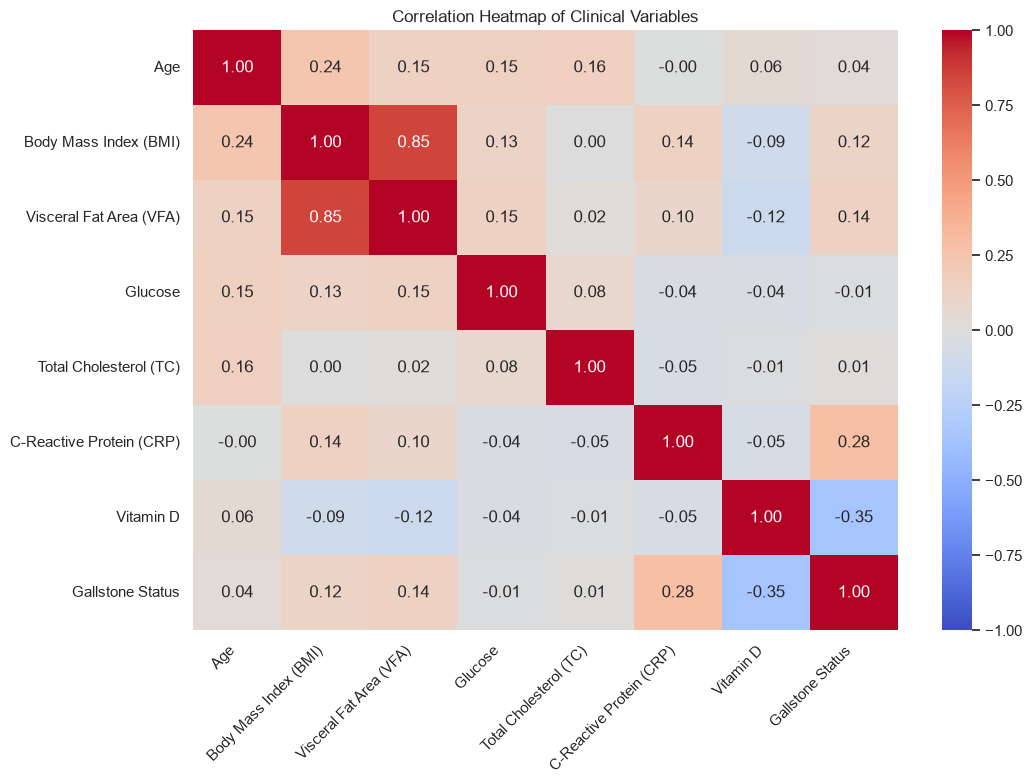

In [122]:
# Correlation Heatmap
# Select variables
features = [
    "Age",
    "Body Mass Index (BMI)",
    "Visceral Fat Area (VFA)",
    "Glucose",
    "Total Cholesterol (TC)",
    "C-Reactive Protein (CRP)",
    "Vitamin D",
    "Gallstone Status"
]

# Calculate correlations
correlation = df[features].corr()

# Create heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Clinical Variables")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [123]:
# Correlation with Gallstone Status
target_corr = df.corr(numeric_only=True)["Gallstone Status"]

# Remove target's correlation with itself
target_corr = target_corr.drop("Gallstone Status").dropna()

# Select top 10 correlations for each category
positive = target_corr[target_corr > 0].nlargest(10)
negative = target_corr[target_corr < 0].nsmallest(10)
near_zero = target_corr.loc[
    target_corr.abs().nsmallest(10).index
]

# Function to display table
def show_table(title, correlations):
    print(f"\n{title}")

    table = correlations.reset_index()
    table.columns = ["Feature", "Correlation"]

    display(
        table.style
        .hide(axis="index")
        .format({"Correlation": "{:+.3f}"})
        .set_properties(**{
            "text-align": "left",
            "padding": "6px 12px"
        })
        .set_properties(
            subset=["Correlation"],
            **{"text-align": "right"}
        )
    )

# Display three separate tables
show_table("Positive Correlations", positive)
show_table("Negative Correlations", negative)
show_table("Near Zero Correlations", near_zero)


Positive Correlations


Feature,Correlation
C-Reactive Protein (CRP),+0.282
Total Body Fat Ratio (TBFR) (%),+0.225
Total Fat Content (TFC),+0.170
Hyperlipidemia,+0.162
High Density Lipoprotein (HDL),+0.159
Gender,+0.153
Visceral Fat Area (VFA),+0.140
Body Mass Index (BMI),+0.122
Alkaline Phosphatase (ALP),+0.110
Diabetes Mellitus (DM),+0.105



Negative Correlations


Feature,Correlation
Vitamin D,-0.355
Lean Mass (LM) (%),-0.226
Bone Mass (BM),-0.217
Hemoglobin (HGB),-0.197
Extracellular Water (ECW),-0.178
Extracellular Fluid/Total Body Water (ECF/TBW),-0.170
Aspartat Aminotransferaz (AST),-0.135
Creatinine,-0.132
Total Body Water (TBW),-0.111
Height,-0.108



Near Zero Correlations


Feature,Correlation
Glucose,-0.011
Total Cholesterol (TC),+0.014
Visceral Fat Rating (VFR),+0.018
Glomerular Filtration Rate (GFR),-0.028
Intracellular Water (ICW),-0.035
Age,+0.036
Alanin Aminotransferaz (ALT),-0.042
Comorbidity,-0.049
Weight,+0.049
Triglyceride,-0.051


### Interpretation

The correlation analysis was conducted to examine the relationships between clinical variables and Gallstone Status and to identify potentially relevant features for machine learning.

**Positive correlations:** CRP (r = 0.282) showed the strongest positive correlation with Gallstone Status, followed by Total Body Fat Ratio (r = 0.225) and Total Fat Content (r = 0.170). This suggests that higher values of these variables are associated with a higher occurrence of gallstones.

**Negative correlations:** Vitamin D (r = −0.355) showed the strongest negative correlation, followed by Lean Mass (r = −0.226) and Bone Mass (r = −0.217). This indicates that higher values of these variables are associated with a lower occurrence of gallstones.

**Near-zero correlations:** Variables such as Glucose (r = −0.011), Total Cholesterol (r = 0.014), and Age (r = 0.036) showed very weak linear relationships with Gallstone Status.

**Correlation heatmap:** A strong positive correlation was observed between BMI and Visceral Fat Area (r = 0.85), indicating that these variables contain overlapping information.

**Overall:** Most variables showed relatively weak individual correlations with Gallstone Status. This suggests that combining multiple clinical features may be more useful for predicting gallstone disease than relying on a single variable. However, correlation does not imply causation, and the predictive importance of these features must be evaluated through machine learning models.

## 2. CRP and Vitamin D Boxplots

Boxplots are used to compare the median, interquartile range, and potential outliers of CRP and Vitamin D between the two groups.

A symmetric logarithmic scale is used for CRP to better display both low and extreme values. Descriptive statistics are calculated to support the visual comparisons.

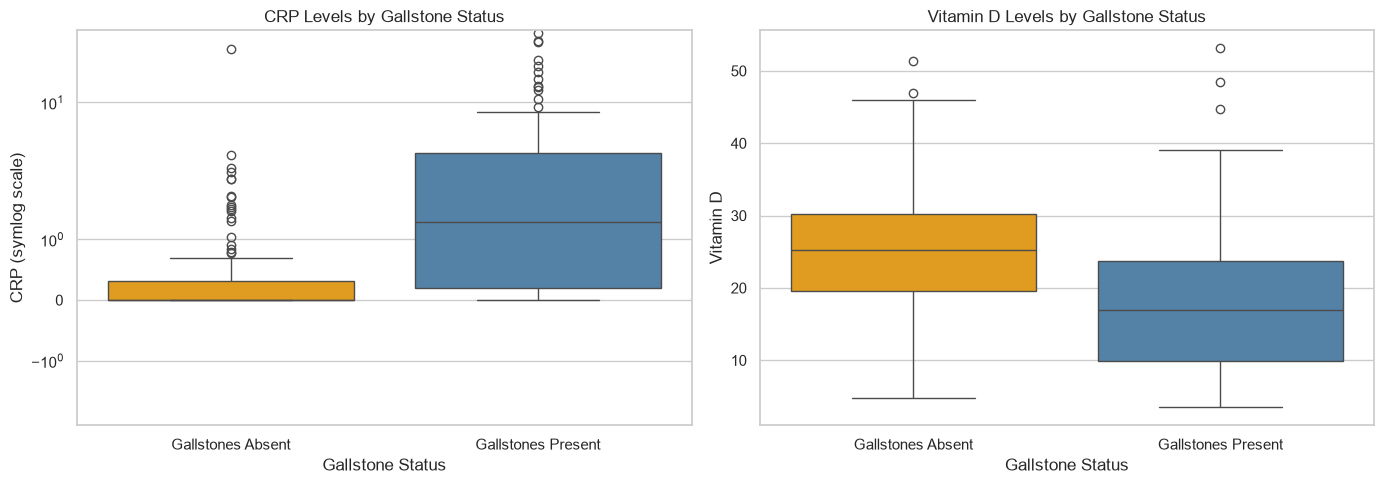

In [124]:
# CRP and Vitamin D boxplots
plt.figure(figsize=(14, 5))

# CRP boxplot
plt.subplot(1, 2, 1)

sns.boxplot(
    data=df,
    x="Gallstone Group",
    y="C-Reactive Protein (CRP)",
    order=group_order,
    hue="Gallstone Group",
    hue_order=group_order,
    palette=colors,
    legend=False
)

plt.title("CRP Levels by Gallstone Status")
plt.xlabel("Gallstone Status")
plt.ylabel("CRP (symlog scale)")
plt.yscale("symlog")

# Vitamin D boxplot
plt.subplot(1, 2, 2)

sns.boxplot(
    data=df,
    x="Gallstone Group",
    y="Vitamin D",
    order=group_order,
    hue="Gallstone Group",
    hue_order=group_order,
    palette=colors,
    legend=False
)

plt.title("Vitamin D Levels by Gallstone Status")
plt.xlabel("Gallstone Status")
plt.ylabel("Vitamin D")

plt.tight_layout()
plt.show()

In [125]:
# CRP statistics
crp_stats = df.groupby("Gallstone Group")["C-Reactive Protein (CRP)"].describe()

# Calculate IQR
crp_stats["IQR"] = crp_stats["75%"] - crp_stats["25%"]

# Display table
print("CRP Statistics")

display(
    crp_stats.reindex(group_order)
    .reset_index()
    .style.hide(axis="index")
    .format({"count": "{:.0f}"}, precision=2)
)

# Vitamin D statistics
vitamin_stats = df.groupby("Gallstone Group")["Vitamin D"].describe()

# Calculate IQR
vitamin_stats["IQR"] = vitamin_stats["75%"] - vitamin_stats["25%"]

# Display table
print("Vitamin D Statistics")

display(
    vitamin_stats.reindex(group_order)
    .reset_index()
    .style.hide(axis="index")
    .format({"count": "{:.0f}"}, precision=2)
)

CRP Statistics


Gallstone Group,count,mean,std,min,25%,50%,75%,max,IQR
Gallstones Absent,161,0.46,2.48,0.00,0.00,0.00,0.31,31.00,0.31
Gallstones Present,158,3.27,6.34,0.00,0.20,1.29,3.45,43.40,3.25


Vitamin D Statistics


Gallstone Group,count,mean,std,min,25%,50%,75%,max,IQR
Gallstones Absent,161,24.90,9.12,4.80,19.62,25.27,30.20,51.40,10.57
Gallstones Present,158,17.83,9.58,3.50,9.95,17.00,23.77,53.10,13.82


**C-Reactive Protein (CRP)**

Patients with gallstones show higher CRP levels, with a median of 1.29 compared to 0.00 for patients without gallstones. The gallstone group also has a higher mean (3.27 vs. 0.46) and greater variability (IQR = 3.25 vs. 0.31). Both groups contain outliers, indicating a right-skewed distribution, particularly among patients with gallstones.

**Vitamin D**

Patients without gallstones have higher Vitamin D levels, with a median of 25.27 compared to 17.00 for patients with gallstones. The mean values show a similar pattern (24.90 vs. 17.83). Although the distributions overlap, the boxplots indicate a noticeable difference between the groups.

**Overall Interpretation**

CRP and Vitamin D show differences between patients with and without gallstones, consistent with the correlation analysis (CRP: r = 0.282; Vitamin D: r = −0.355). These findings suggest that both variables may be useful predictors in machine learning models. However, the overlap between the groups indicates that neither variable alone can reliably distinguish patients with gallstones from those without.

### CRP Outlier Analysis Using the IQR Method

In [126]:
# CRP Outlier Analysis using the IQR method
crp = "C-Reactive Protein (CRP)"

results = []

for group in group_order:
    values = df.loc[df["Gallstone Group"] == group, crp].dropna()

    # Calculate IQR
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    # Define outlier boundaries
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = values[(values < lower) | (values > upper)]

    results.append({
        "Gallstone Group": group,
        "Total Patients": len(values),
        "CRP Outliers": len(outliers),
        "Outliers (%)": len(outliers) / len(values) * 100,
        "Maximum CRP": values.max()
    })

# Display results
outlier_table = pd.DataFrame(results)

display(
    outlier_table.style
    .hide(axis="index")
    .format({
        "Outliers (%)": "{:.1f}%",
        "Maximum CRP": "{:.2f}"
    })
)

Gallstone Group,Total Patients,CRP Outliers,Outliers (%),Maximum CRP
Gallstones Absent,161,19,11.8%,31.00
Gallstones Present,158,12,7.6%,43.40


### Interpretation – CRP Outlier Analysis

The analysis identified several potential outliers in CRP levels, indicating that some patients have considerably higher CRP values than others. This suggests a skewed distribution with substantial variation between patients.

These extreme values may influence certain machine learning models and should therefore be considered during preprocessing.

## 3. Relationship Between BMI and Visceral Fat Area

A scatterplot with a linear trendline is used to examine the relationship between BMI and Visceral Fat Area (VFA).

The observations are colored by gallstone status to investigate whether the relationship differs between the two patient groups. Pearson correlation coefficients are calculated for the complete dataset and each group separately.

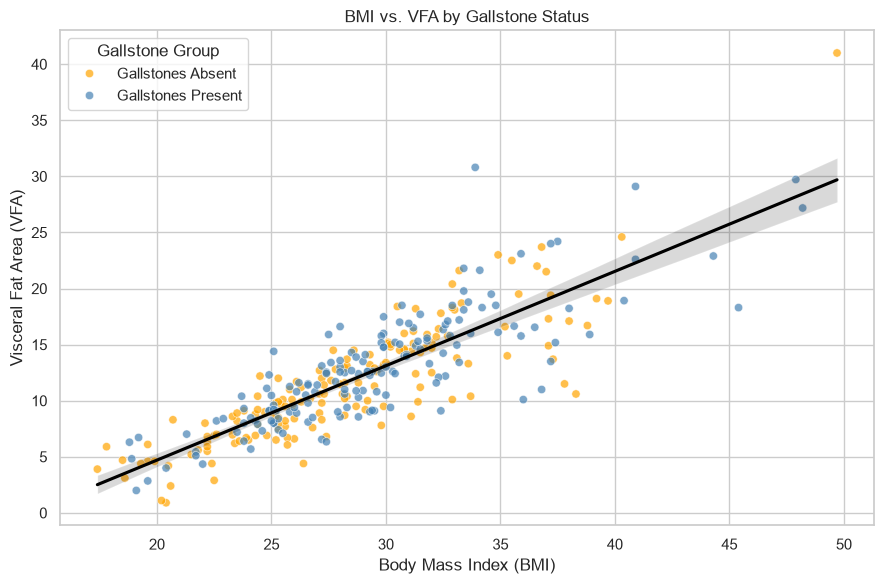

All patients: 0.85
Gallstones Absent: 0.864
Gallstones Present: 0.829


In [127]:
# BMI vs. VFA with trendline
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Body Mass Index (BMI)",
    y="Visceral Fat Area (VFA)",
    hue="Gallstone Group",
    hue_order=group_order,
    palette=colors,
    alpha=0.7
)

sns.regplot(
    data=df,
    x="Body Mass Index (BMI)",
    y="Visceral Fat Area (VFA)",
    scatter=False,
    color="black"
)

plt.title("BMI vs. VFA by Gallstone Status")
plt.xlabel("Body Mass Index (BMI)")
plt.ylabel("Visceral Fat Area (VFA)")
plt.legend(title="Gallstone Group")
plt.tight_layout()
plt.show()


# Correlation between BMI and VFA
# All patients
correlation = df["Body Mass Index (BMI)"].corr(
    df["Visceral Fat Area (VFA)"]
)

# Patients without gallstones (0)
group_0 = df[df["Gallstone Status"] == 0]
corr_0 = group_0["Body Mass Index (BMI)"].corr(
    group_0["Visceral Fat Area (VFA)"]
)

# Patients with gallstones (1)
group_1 = df[df["Gallstone Status"] == 1]
corr_1 = group_1["Body Mass Index (BMI)"].corr(
    group_1["Visceral Fat Area (VFA)"]
)

print("All patients:", round(correlation, 3))
print("Gallstones Absent:", round(corr_0, 3))
print("Gallstones Present:", round(corr_1, 3))

### Interpretation

The scatterplot shows a strong positive correlation between BMI and Visceral Fat Area (VFA), with an overall correlation coefficient of r = 0.85. This indicates that patients with higher BMI generally tend to have higher levels of visceral fat.

The two patient groups show considerable overlap, suggesting that BMI and VFA alone do not clearly distinguish between patients with and without gallstones.

The strong correlation also suggests that BMI and VFA contain overlapping information, which may be relevant when selecting features for machine learning models. However, both variables may still contribute useful predictive information and should be evaluated during model training.

## 4. Key Findings from Exploratory Data Analysis

The exploratory analysis identified several relationships between clinical variables and Gallstone Status.

**Correlation Analysis:** Vitamin D showed the strongest absolute correlation with Gallstone Status (r = −0.355), followed by CRP (r = 0.282). Most other variables showed relatively weak correlations.

**CRP and Vitamin D:** Patients with gallstones had higher median CRP levels (1.29 vs. 0.00) and lower median Vitamin D levels (17.00 vs. 25.27) compared to patients without gallstones. However, the distributions showed considerable overlap, indicating that neither variable alone clearly separates the two groups.

**BMI and VFA:** A strong positive correlation was observed between BMI and Visceral Fat Area (r = 0.850), suggesting that these variables contain overlapping information. The relationship was similarly strong in patients without gallstones (r = 0.864) and with gallstones (r = 0.829).

**Potential Outliers:** CRP showed a skewed distribution with several extreme observations. These values should be assessed during preprocessing rather than automatically removed.

### Implications for Machine Learning

The findings suggest that Vitamin D and CRP may be relevant features for predicting gallstone disease, while BMI and VFA may provide partly overlapping information.

However, correlation does not imply causation or establish predictive importance. Further preprocessing, model training and evaluation on unseen data are necessary to determine which features contribute most to classification performance.